In [5]:

from pathlib import Path
import sys
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("ML folder exists:", (PROJECT_ROOT / "ml").is_dir())

from ml.src.train_forecast import prepare_forecast_data
from ml.src.training_common import chronological_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare forecasting dataset
forecast_df, numeric_features, categorical_features = prepare_forecast_data()

print("\nDataset shape:", forecast_df.shape)
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

display(forecast_df.head(10))

# 2. Chronological train-test split
train_df, test_df, cutoff = chronological_split(
    forecast_df, "target_date"
)

feature_columns = numeric_features + categorical_features
target = "target_units_sold"

print("\nTrain rows:", len(train_df))
print("Test rows:", len(test_df))
print("Test cutoff:", cutoff)

print("\nTrain dates:")
print(train_df["target_date"].min(), "to", train_df["target_date"].max())

print("\nTest dates:")
print(test_df["target_date"].min(), "to", test_df["target_date"].max())

# 3. Prepare features and target
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[target]
y_test = test_df[target]

# 4. Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# 5. Train Random Forest model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

# 6. Make predictions
predictions = model.predict(X_test)

# 7. Evaluate model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n--- Demand Forecasting Results ---")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2:   {r2:.3f}")

# 8. Compare actual and predicted values
results_df = test_df[
    ["target_date", "product_id", "category", target]
].copy()

results_df["predicted_units_sold"] = predictions
results_df["predicted_units_sold"] = (
    results_df["predicted_units_sold"].clip(lower=0).round(2)
)

display(results_df.head(20))


Project root: d:\machine learning_project\WasteWise-AI\WasteWise-AI
ML folder exists: True

Dataset shape: (1520, 17)

Numeric features: ['sales_lag_1', 'sales_lag_7', 'sales_lag_28', 'sales_mean_7d', 'sales_mean_28d', 'unit_price_lag_1', 'discount_pct_lag_1', 'promotion_active_lag_1', 'calendar_day_of_week', 'calendar_month', 'calendar_day_of_year_sin', 'calendar_day_of_year_cos', 'calendar_is_weekend']

Categorical features: ['product_id', 'category']


,target_date,product_id,category,target_units_sold,sales_lag_1,sales_lag_7,sales_lag_28,unit_price_lag_1,discount_pct_lag_1,promotion_active_lag_1,sales_mean_7d,sales_mean_28d,calendar_day_of_week,calendar_month,calendar_day_of_year_sin,calendar_day_of_year_cos,calendar_is_weekend
0,2026-04-29,1001,Dairy,11,17.0,16.0,6.0,32.0,0.0,0,12.571429,11.535714,2,4,0.888701,-0.458487,0
1,2026-04-29,1002,Dairy,28,34.0,26.0,23.0,22.5,10.0,1,31.142857,32.928571,2,4,0.888701,-0.458487,0
2,2026-04-29,1003,Bakery,27,23.0,25.0,32.0,40.0,0.0,0,30.857143,28.607143,2,4,0.888701,-0.458487,0
3,2026-04-29,1004,Dairy,19,14.0,10.0,25.0,85.0,0.0,0,21.428571,21.750000,2,4,0.888701,-0.458487,0
4,2026-04-29,1005,Produce,24,19.0,23.0,19.0,30.0,0.0,0,21.285714,21.642857,2,4,0.888701,-0.458487,0
5,2026-04-29,1006,Produce,36,39.0,35.0,32.0,45.0,0.0,0,37.000000,35.535714,2,4,0.888701,-0.458487,0
6,2026-04-29,1007,Produce,15,0.0,15.0,11.0,120.0,0.0,0,9.285714,11.428571,2,4,0.888701,-0.458487,0
7,2026-04-29,1008,Beverage,43,16.0,28.0,30.0,95.0,0.0,0,27.000000,29.071429,2,4,0.888701,-0.458487,0
8,2026-04-29,1009,Dairy,10,16.0,14.0,13.0,60.0,0.0,0,15.000000,14.500000,2,4,0.888701,-0.458487,0
9,2026-04-29,1010,Bakery,15,11.0,8.0,11.0,55.0,0.0,0,12.000000,11.678571,2,4,0.888701,-0.458487,0



Train rows: 1210
Test rows: 310
Test cutoff: 2026-08-28 00:00:00

Train dates:
2026-04-29 00:00:00 to 2026-08-27 00:00:00

Test dates:
2026-08-28 00:00:00 to 2026-09-27 00:00:00

--- Demand Forecasting Results ---
MAE:  3.987
RMSE: 5.094
R2:   0.706


,target_date,product_id,category,target_units_sold,predicted_units_sold
1210,2026-08-28,1001,Dairy,11,10.26
1211,2026-08-28,1002,Dairy,16,23.88
1212,2026-08-28,1003,Bakery,29,21.88
1213,2026-08-28,1004,Dairy,28,18.86
1214,2026-08-28,1005,Produce,17,17.96
1215,2026-08-28,1006,Produce,26,30.90
1216,2026-08-28,1007,Produce,10,11.34
1217,2026-08-28,1008,Beverage,24,22.40
1218,2026-08-28,1009,Dairy,9,11.53
1219,2026-08-28,1010,Bakery,8,11.98


In [6]:

# Separate input features and target

feature_columns = numeric_features + categorical_features
target = "target_units_sold"

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[target]
y_test = test_df[target]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (1210, 15)
X_test shape: (310, 15)
y_train shape: (1210,)
y_test shape: (310,)


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Handle numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Handle categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Demand Forecasting Model trained successfully!")


Demand Forecasting Model trained successfully!


In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
predictions = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Demand Forecasting Model Evaluation")
print("-----------------------------------")
print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R2   : {r2:.3f}")


Demand Forecasting Model Evaluation
-----------------------------------
MAE  : 3.987
RMSE : 5.094
R2   : 0.706


In [9]:

results_df = test_df[
    ["target_date", "product_id", "category", "target_units_sold"]
].copy()

results_df["predicted_units_sold"] = predictions.round(2)

results_df = results_df.rename(columns={
    "target_units_sold": "actual_units_sold"
})

display(results_df.head(20))


,target_date,product_id,category,actual_units_sold,predicted_units_sold
1210,2026-08-28,1001,Dairy,11,10.26
1211,2026-08-28,1002,Dairy,16,23.88
1212,2026-08-28,1003,Bakery,29,21.88
1213,2026-08-28,1004,Dairy,28,18.86
1214,2026-08-28,1005,Produce,17,17.96
1215,2026-08-28,1006,Produce,26,30.90
1216,2026-08-28,1007,Produce,10,11.34
1217,2026-08-28,1008,Beverage,24,22.40
1218,2026-08-28,1009,Dairy,9,11.53
1219,2026-08-28,1010,Bakery,8,11.98


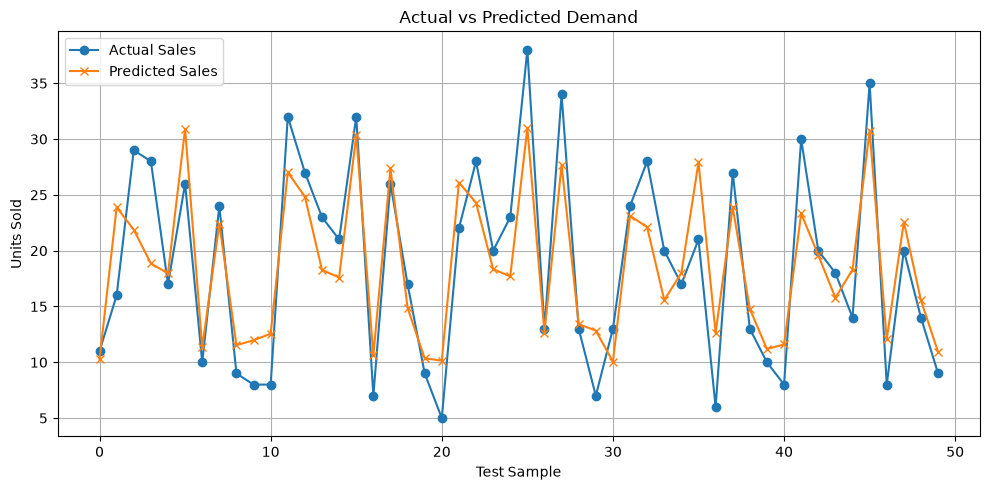

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.iloc[:50].to_numpy(),
    label="Actual Sales",
    marker="o"
)

plt.plot(
    predictions[:50],
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Demand")
plt.xlabel("Test Sample")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
